In [1]:
import os, glob
print("Working dir:", os.getcwd())
print("data folder contents:", os.listdir("../data") if os.path.exists("../data") else "data folder NOT FOUND")
print("Downloads matches:", glob.glob(os.path.expanduser("~/Downloads/*creditcard*")))

Working dir: C:\Users\anshi\Credit_card_fraud_detection_repo\code
data folder contents: ['creditcard.csv', 'README.md']
Downloads matches: []


In [2]:
import zipfile, os
zip_path = os.path.expanduser("~/Downloads/archive (1).zip")
with zipfile.ZipFile(zip_path) as z:
    z.extract("creditcard.csv", "../data")
print(os.listdir("../data"))

['creditcard.csv', 'README.md']


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [4]:
pd.set_option('display.max_columns', 500)

In [5]:
# =============================================================
# IMPORTANT — Read before running!
# =============================================================
# Step 1: Download creditcard.csv from Kaggle:
#   https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
#
# Step 2: Place creditcard.csv inside the /data/ folder:
#   Credit_card_fraud_detection_repo/
#   data/
#       creditcard.csv   <-- PUT IT HERE
#
# Step 3: Choose your path option below and edit if needed.
# =============================================================

import os

# Option A: Relative path (default)
# Works when Jupyter is launched from inside the /code/ folder
csv_path = "../data/creditcard.csv"

# Option B: Windows absolute path
# Uncomment and edit the line below if Option A gives FileNotFoundError
# csv_path = r"C:\Users\YourName\Downloads\Credit_card_fraud_detection_repo-main\Credit_card_fraud_detection_repo-main\data\creditcard.csv"

# Option C: Mac / Linux absolute path
# csv_path = "/home/yourname/Credit_card_fraud_detection_repo/data/creditcard.csv"

if not os.path.exists(csv_path):
    print("ERROR: creditcard.csv not found at:", os.path.abspath(csv_path))
    print("")
    print("How to fix:")
    print("  1. Download from: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud")
    print("  2. Place creditcard.csv inside the /data/ folder of this repo")
    print("  3. Or update csv_path above with your full absolute path")
    raise FileNotFoundError("Dataset not found. See printed instructions above.")

df = pd.read_csv(csv_path)
print("Dataset loaded successfully! Shape:", df.shape)
df.head()


Dataset loaded successfully! Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
df.shape

(284807, 31)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [8]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,2.236957e-15,1.724421e-15,-1.245415e-15,8.238900e-16,1.213481e-15,4.866699e-15,1.436219e-15,-3.768179e-16,9.771718e-16,1.037846e-15,6.418678e-16,1.596686e-16,-3.576577e-16,2.618565e-16,4.473116e-15,5.109395e-16,1.686100e-15,-3.657409e-16,-1.221465e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,1.020713e+00,9.992014e-01,9.952742e-01,9.585956e-01,9.153160e-01,8.762529e-01,8.493371e-01,8.381762e-01,8.140405e-01,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,-4.797473e+00,-1.868371e+01,-5.791881e+00,-1.921433e+01,-4.498945e+00,-1.412985e+01,-2.516280e+01,-9.498746e+00,-7.213527e+00,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,-7.624942e-01,-4.055715e-01,-6.485393e-01,-4.255740e-01,-5.828843e-01,-4.680368e-01,-4.837483e-01,-4.988498e-01,-4.562989e-01,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,-3.275735e-02,1.400326e-01,-1.356806e-02,5.060132e-02,4.807155e-02,6.641332e-02,-6.567575e-02,-3.636312e-03,3.734823e-03,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,7.395934e-01,6.182380e-01,6.625050e-01,4.931498e-01,6.488208e-01,5.232963e-01,3.996750e-01,5.008067e-01,4.589494e-01,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,1.201891e+01,7.848392e+00,7.126883e+00,1.052677e+01,8.877742e+00,1.731511e+01,9.253526e+00,5.041069e+00,5.591971e+00,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [9]:
df_missing_columns = (round(((df.isnull().sum()/len(df.index))*100),2).to_frame('null')).sort_values('null', ascending=False)
df_missing_columns


,null
Time,0.0
V1,0.0
V2,0.0
V3,0.0
V4,0.0
V5,0.0
V6,0.0
V7,0.0
V8,0.0
V9,0.0


In [10]:
classes = df['Class'].value_counts()
classes

Class
0    284315
1       492
Name: count, dtype: int64

In [11]:
normal_share = round((classes[0]/df['Class'].count()*100),2)
normal_share

np.float64(99.83)

In [12]:
fraud_share = round((classes[1]/df['Class'].count()*100),2)
fraud_share


np.float64(0.17)

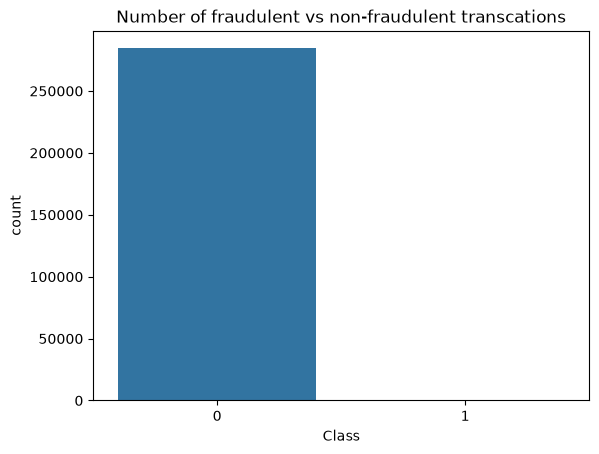

In [13]:
sns.countplot(x='Class', data=df)
plt.title('Number of fraudulent vs non-fraudulent transcations')
plt.show()

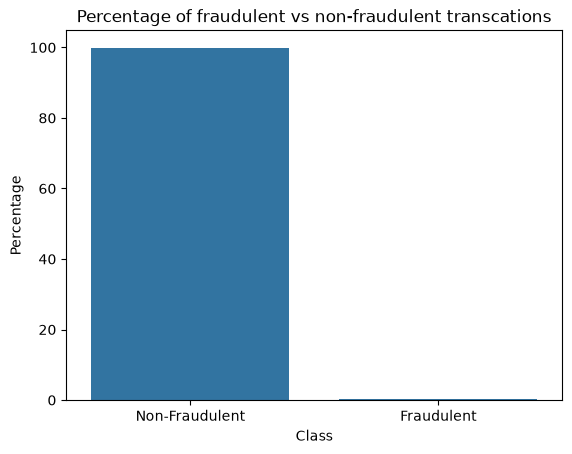

In [14]:
fraud_percentage = {'Class':['Non-Fraudulent', 'Fraudulent'], 'Percentage':[normal_share, fraud_share]} 
df_fraud_percentage = pd.DataFrame(fraud_percentage) 
sns.barplot(x='Class',y='Percentage', data=df_fraud_percentage)
plt.title('Percentage of fraudulent vs non-fraudulent transcations')
plt.show()

In [15]:
data_fraud = df[df['Class'] == 1]

In [16]:
data_non_fraud = df[df['Class'] == 0]

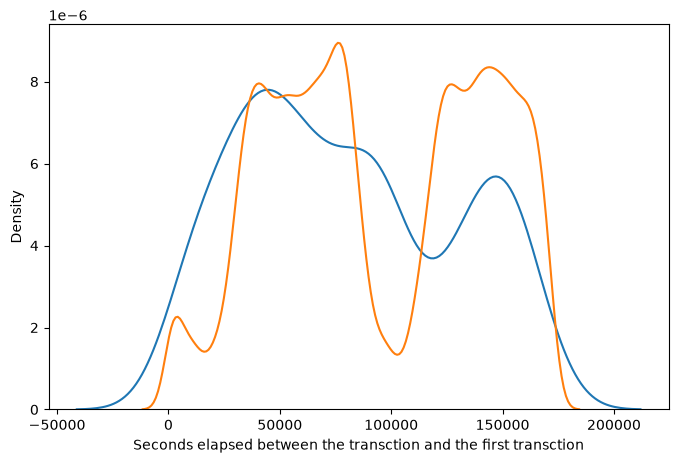

In [17]:
plt.figure(figsize=(8,5))
ax = sns.distplot(data_fraud['Time'],label='fraudulent',hist=False)
ax = sns.distplot(data_non_fraud['Time'],label='non fraudulent',hist=False)
ax.set(xlabel='Seconds elapsed between the transction and the first transction')
plt.show()

In [18]:
df.drop('Time', axis=1, inplace=True)

In [19]:
from sklearn.model_selection import train_test_split

In [20]:
X = df.drop(['Class'], axis=1)

In [21]:
y = df['Class']

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, test_size=0.2, random_state=100)

In [23]:
from sklearn.preprocessing import StandardScaler

In [24]:
scaler = StandardScaler()

In [25]:
X_train['Amount'] = scaler.fit_transform(X_train[['Amount']])

In [26]:
X_train.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
201788,2.023734,-0.429219,-0.691061,-0.201461,-0.162486,0.283718,-0.674694,0.192230,1.124319,-0.037763,0.308648,0.875063,-0.009562,0.116038,0.086537,0.628337,-0.997868,0.482547,0.576077,-0.171390,-0.195207,-0.477813,0.340513,0.059174,-0.431015,-0.297028,-0.000063,-0.046947,-0.345273
179369,-0.145286,0.736735,0.543226,0.892662,0.350846,0.089253,0.626708,-0.049137,-0.732566,0.297692,0.519027,0.041275,-0.690783,0.647121,0.526333,-1.098558,0.511739,0.243984,3.349611,0.206709,-0.124288,-0.263560,-0.110568,-0.434224,-0.509076,0.719784,-0.006357,0.146053,-0.206439
73138,-3.015846,-1.920606,1.229574,0.721577,1.089918,-0.195727,-0.462586,0.919341,-0.612193,-0.966197,1.106534,1.026421,-0.474229,0.641488,-0.430684,-0.631257,0.634633,-0.718062,-0.039929,0.842838,0.274911,-0.319550,0.212891,-0.268792,0.241190,0.318445,-0.100726,-0.365257,0.358043
208679,1.851980,-1.007445,-1.499762,-0.220770,-0.568376,-1.232633,0.248573,-0.539483,-0.813368,0.785431,-0.784316,0.673626,1.428269,0.043937,-0.309507,-1.805728,-0.012118,0.377096,-0.658353,-0.196551,-0.406722,-0.899081,0.137370,0.075894,-0.244027,0.455618,-0.094066,-0.031488,0.362400
206534,2.237844,-0.551513,-1.426515,-0.924369,-0.401734,-1.438232,-0.119942,-0.449263,-0.717258,0.851668,-0.497634,-0.445482,0.324575,0.125543,0.266588,0.802640,0.225312,-1.865494,0.621879,-0.045417,0.050447,0.125601,0.215531,-0.080485,-0.063975,-0.307176,-0.042838,-0.063872,-0.316109


In [27]:
X_test['Amount'] = scaler.transform(X_test[['Amount']])
X_test.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
49089,1.229452,-0.235478,-0.627166,0.419877,1.797014,4.069574,-0.896223,1.036103,0.745991,-0.147304,-0.850459,0.397845,-0.259849,-0.277065,-0.766810,-0.200946,-0.338122,0.006032,0.477431,-0.057922,-0.170060,-0.288750,-0.130270,1.025935,0.847990,-0.271476,0.060052,0.018104,-0.340485
154704,2.016893,-0.088751,-2.989257,-0.142575,2.675427,3.332289,-0.652336,0.752811,1.962566,-1.025024,1.126976,-2.418093,1.250341,-0.056209,-0.736695,0.014783,1.890249,0.333755,-0.450398,-0.147619,-0.184153,-0.089661,0.087188,0.570679,0.101899,0.620842,-0.048958,-0.042831,-0.320859
67247,0.535093,-1.469185,0.868279,0.385462,-1.439135,0.368118,-0.499370,0.303698,1.042073,-0.437209,1.145725,0.907573,-1.095634,-0.055080,-0.621880,-0.191066,0.311988,-0.478635,0.231159,0.437685,0.028010,-0.384708,-0.128376,0.286638,-0.136700,0.913904,-0.083364,0.052485,0.853442
251657,2.128486,-0.117215,-1.513910,0.166456,0.359070,-0.540072,0.116023,-0.216140,0.680314,0.079977,-1.705327,-0.127579,-0.207945,0.307878,0.213491,0.163032,-0.587029,-0.561292,0.472667,-0.227278,-0.357993,-0.905085,0.223474,-1.075605,-0.188519,0.267672,-0.071733,-0.072238,-0.344410
201903,0.558593,1.587908,-2.368767,5.124413,2.171788,-0.500419,1.059829,-0.254233,-1.959060,0.948915,-0.288169,-1.007647,0.470316,-2.771902,0.221958,0.354333,2.603189,1.092576,0.668084,0.249457,-0.035049,0.271455,0.381606,0.332001,-0.334757,0.448890,0.168585,0.004955,-0.229480


In [28]:
cols = X_train.columns
cols

Index(['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11',
       'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21',
       'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount'],
      dtype='str')

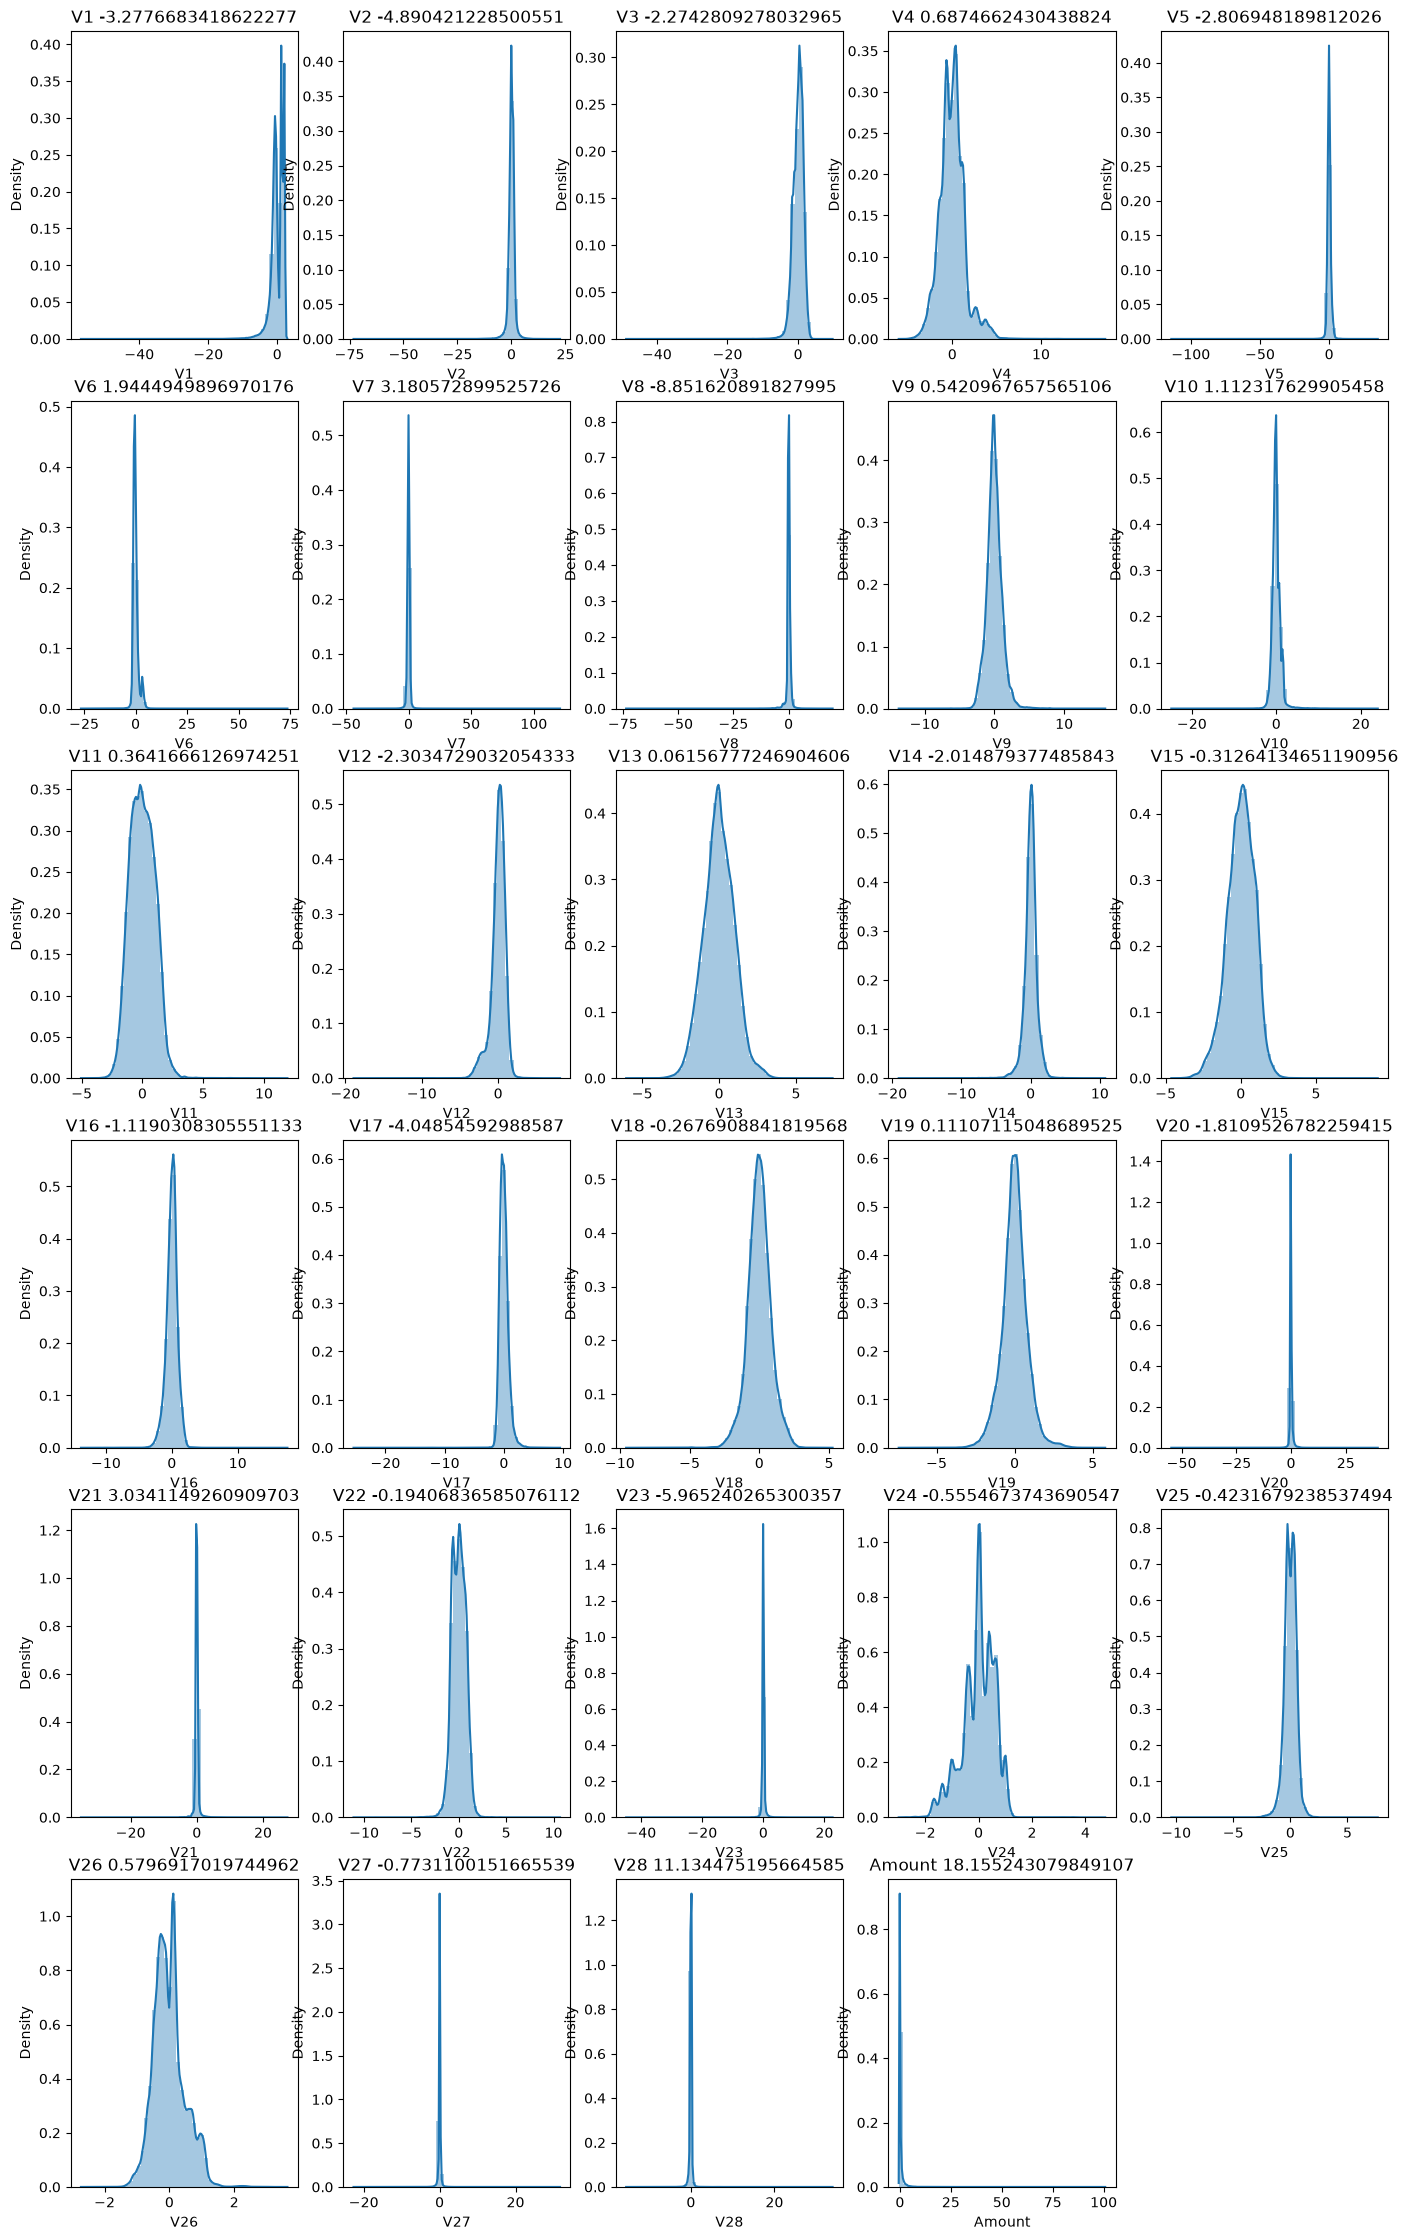

In [29]:
k=0
plt.figure(figsize=(17,28))
for col in cols :    
    k=k+1
    plt.subplot(6, 5,k)    
    sns.distplot(X_train[col])
    plt.title(col+' '+str(X_train[col].skew()))

In [30]:
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.neighbors import KNeighborsClassifier as KNN
from sklearn.linear_model import LogisticRegression as pp
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report

In [31]:
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV

In [32]:
folds = KFold(n_splits=5, shuffle=True, random_state=4)

In [33]:
params = {"C": [0.01, 0.1, 1, 10, 100, 1000]}

In [34]:
model_cv = GridSearchCV(estimator = pp(),
                        param_grid = params, 
                        scoring= 'roc_auc', 
                        cv = folds, 
                        verbose = 1,
                        return_train_score=True) 

In [35]:
model_cv.fit(X_train, y_train)

Fitting 5 folds for each of 6 candidates, totalling 30 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegression()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute 

In [36]:
cv_results = pd.DataFrame(model_cv.cv_results_)
cv_results

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score
0,0.332644,0.064886,0.021691,0.002699,0.01,{'C': 0.01},0.990164,0.986901,0.961656,0.981826,0.994908,0.983091,0.011535,1,0.982898,0.983474,0.988951,0.985696,0.982194,0.984643,0.002453
1,0.321038,0.028146,0.019519,0.003778,0.10,{'C': 0.1},0.988704,0.985957,0.946637,0.980769,0.993755,0.979164,0.016797,2,0.979734,0.981928,0.986449,0.983659,0.979819,0.982318,0.002527
2,0.426485,0.029094,0.021411,0.002301,1.00,{'C': 1},0.988224,0.985444,0.938839,0.975737,0.992757,0.976200,0.019495,3,0.975446,0.981099,0.984576,0.978482,0.978537,0.979628,0.003054
3,0.434180,0.044389,0.024350,0.001240,10.00,{'C': 10},0.988233,0.985055,0.937772,0.975085,0.992734,0.975776,0.019868,6,0.975300,0.980501,0.984220,0.977795,0.978492,0.979261,0.002985
4,0.433311,0.042817,0.023609,0.000704,100.00,{'C': 100},0.988083,0.985069,0.937615,0.975659,0.992729,0.975831,0.019907,4,0.975993,0.980509,0.984162,0.978321,0.978486,0.979494,0.002737
5,0.417566,0.030179,0.025794,0.002356,1000.00,{'C': 1000},0.988084,0.985070,0.937597,0.975667,0.992729,0.975829,0.019914,5,0.975990,0.980510,0.984155,0.978329,0.978486,0.979494,0.002736


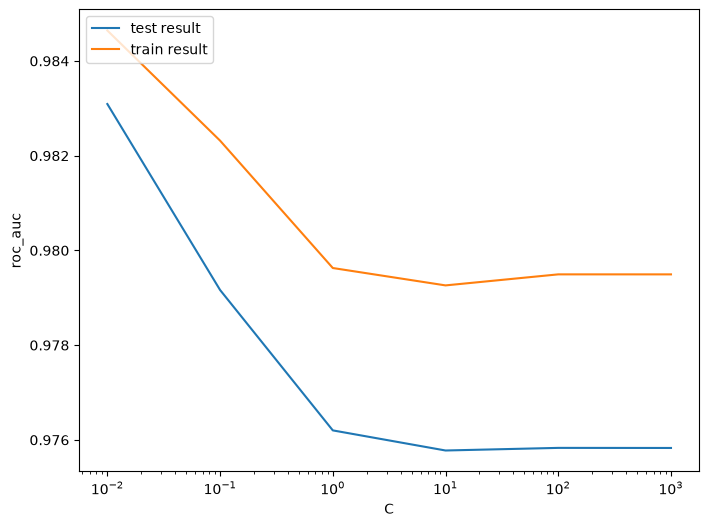

In [37]:
plt.figure(figsize=(8, 6))
plt.plot(cv_results['param_C'], cv_results['mean_test_score'])
plt.plot(cv_results['param_C'], cv_results['mean_train_score'])
plt.xlabel('C')
plt.ylabel('roc_auc')
plt.legend(['test result', 'train result'], loc='upper left')
plt.xscale('log')

In [38]:
best_score = model_cv.best_score_
best_C = model_cv.best_params_['C']

print(" The highest test roc_auc is {0} at C = {1}".format(best_score, best_C))

 The highest test roc_auc is 0.9830907583052021 at C = 0.01


In [39]:
logistic_imb = pp(C=0.01)

In [40]:
logistic_imb_model = logistic_imb.fit(X_train, y_train)

In [41]:
y_train_pred = logistic_imb_model.predict(X_train)

In [42]:
confusion = metrics.confusion_matrix(y_train, y_train_pred)
print(confusion)

[[227426     23]
 [   146    250]]


In [43]:
TP = confusion[1,1] 
TN = confusion[0,0] 
FP = confusion[0,1] 
FN = confusion[1,0]

In [44]:
print("Accuracy:-",metrics.accuracy_score(y_train, y_train_pred))
print("Sensitivity:-",TP / float(TP+FN))
print("Specificity:-", TN / float(TN+FP))
print("F1-Score:-", f1_score(y_train, y_train_pred))

Accuracy:- 0.9992582676819768
Sensitivity:- 0.6313131313131313
Specificity:- 0.9998988784298898
F1-Score:- 0.7473841554559043


In [45]:
folds = KFold(n_splits=3, shuffle=True, random_state=4)

In [46]:
params = {"n_neighbors": [5, 10]}

In [47]:
model_cv = GridSearchCV(estimator=KNN(),
                        param_grid=params,
                        scoring='roc_auc',
                        cv=folds,
                        verbose=1,
                        return_train_score=True)

In [48]:
model_cv.fit(X_train, y_train)

Fitting 3 folds for each of 2 candidates, totalling 6 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_neighbors': [5, 10]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribu

In [49]:
best_score = model_cv.best_score_
best_k = model_cv.best_params_['n_neighbors']
print("The highest test ROC AUC is {0} at k = {1}".format(best_score, best_k))

The highest test ROC AUC is 0.933877820175952 at k = 10


In [50]:
knn_imb = KNN(n_neighbors=best_k)

In [51]:
knn_imb.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [52]:
y_train_pred = knn_imb.predict(X_train)

In [53]:
confusion = confusion_matrix(y_train, y_train_pred)
print("Confusion Matrix:")
print(confusion)

Confusion Matrix:
[[227427     22]
 [    91    305]]


In [54]:
TP = confusion[1, 1]
TN = confusion[0, 0]
FP = confusion[0, 1]
FN = confusion[1, 0]

In [55]:
print("Accuracy:", metrics.accuracy_score(y_train, y_train_pred))
print("Sensitivity:", TP / float(TP + FN))
print("Specificity:", TN / float(TN + FP))
print("F1-Score:", f1_score(y_train, y_train_pred))

Accuracy: 0.9995040488051088
Sensitivity: 0.7702020202020202
Specificity: 0.9999032750198946
F1-Score: 0.8437067773167358


In [56]:
from sklearn.tree import DecisionTreeClassifier

In [57]:
param_grid = {
    'max_depth': range(5, 15, 5),
    'min_samples_leaf': range(50, 150, 50),
    'min_samples_split': range(50, 150, 50),
}


In [58]:
dtree = DecisionTreeClassifier()

In [59]:
grid_search = GridSearchCV(estimator = dtree, 
                           param_grid = param_grid, 
                           scoring= 'roc_auc',
                           cv = 3, 
                           verbose = 1)

In [60]:
grid_search.fit(X_train,y_train)

Fitting 3 folds for each of 8 candidates, totalling 24 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': range(5, 15, 5), 'min_samples_leaf': range(50, 150, 50), 'min_samples_split': range(50, 150, 50)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_se

In [61]:
cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_max_depth,param_min_samples_leaf,param_min_samples_split,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
0,3.592107,0.077933,0.036205,0.002249,5,50,50,"{'max_depth': 5, 'min_samples_leaf': 50, 'min_...",0.933337,0.933183,0.923871,0.930130,0.004427,6
1,3.541225,0.002591,0.036096,0.005171,5,50,100,"{'max_depth': 5, 'min_samples_leaf': 50, 'min_...",0.933337,0.933183,0.923883,0.930134,0.004421,5
2,3.548794,0.009921,0.035412,0.004163,5,100,50,"{'max_depth': 5, 'min_samples_leaf': 100, 'min...",0.933279,0.936720,0.944598,0.938199,0.004738,2
3,3.561590,0.044104,0.031603,0.004800,5,100,100,"{'max_depth': 5, 'min_samples_leaf': 100, 'min...",0.933282,0.936720,0.944598,0.938200,0.004737,1
4,7.354615,0.209154,0.040017,0.003851,10,50,50,"{'max_depth': 10, 'min_samples_leaf': 50, 'min...",0.917528,0.916438,0.930517,0.921494,0.006395,8
5,7.424694,0.057179,0.033457,0.002715,10,50,100,"{'max_depth': 10, 'min_samples_leaf': 50, 'min...",0.924938,0.916433,0.937996,0.926456,0.008868,7
6,7.273905,0.046968,0.037122,0.004466,10,100,50,"{'max_depth': 10, 'min_samples_leaf': 100, 'mi...",0.933469,0.919682,0.944106,0.932419,0.009999,3
7,7.248958,0.058624,0.041722,0.007213,10,100,100,"{'max_depth': 10, 'min_samples_leaf': 100, 'mi...",0.933462,0.919653,0.944085,0.932400,0.010003,4


In [62]:
dt_imb_model = DecisionTreeClassifier(criterion = "gini", 
                                  random_state = 100,
                                  max_depth=5, 
                                  min_samples_leaf=100,
                                  min_samples_split=100)

dt_imb_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",100
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",100
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [63]:
y_train_pred = dt_imb_model.predict(X_train)

In [64]:
confusion = metrics.confusion_matrix(y_train, y_train_pred)
print(confusion)


[[227374     75]
 [   114    282]]


In [65]:
TP = confusion[1, 1]  
TN = confusion[0, 0] 
FP = confusion[0, 1] 
FN = confusion[1, 0] 

In [66]:
print("Accuracy:", metrics.accuracy_score(y_train, y_train_pred))
print("Sensitivity:", TP / float(TP + FN))
print("Specificity:", TN / float(TN + FP))
print("F1-Score:", f1_score(y_train, y_train_pred))

Accuracy: 0.9991704887094297
Sensitivity: 0.7121212121212122
Specificity: 0.9996702557496405
F1-Score: 0.749003984063745


In [67]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

In [68]:
param_grid = {
    'max_depth': [5],
    'min_samples_leaf': [50],
    'min_samples_split': [50],
    'n_estimators': [100], 
    'max_features': [10]
}

In [69]:
rf = RandomForestClassifier()

In [70]:
grid_search = GridSearchCV(estimator=rf, 
                           param_grid=param_grid, 
                           cv=2,  # Use fewer folds
                           n_jobs=-1,
                           verbose=1, 
                           return_train_score=True)

In [71]:
grid_search.fit(X_train, y_train)


Fitting 2 folds for each of 1 candidates, totalling 2 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [5], 'max_features': [10], 'min_samples_leaf': [50], 'min_samples_split': [50], ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",2
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_i

In [72]:
best_rf_model = grid_search.best_estimator_

In [73]:
best_rf_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",50
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",50
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",10
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_tr

In [74]:
y_train_pred = best_rf_model.predict(X_train)

In [75]:
confusion = metrics.confusion_matrix(y_train, y_train_pred)
print("Confusion Matrix:")
print(confusion)

Confusion Matrix:
[[227412     37]
 [   109    287]]


In [76]:
TP = confusion[1, 1]  
TN = confusion[0, 0] 
FP = confusion[0, 1] 
FN = confusion[1, 0]

In [77]:
print("Accuracy:", metrics.accuracy_score(y_train, y_train_pred))
print("Sensitivity:", TP / float(TP + FN))
print("Specificity:", TN / float(TN + FP))
print("F1-Score:", f1_score(y_train, y_train_pred))

Accuracy: 0.999359213500406
Sensitivity: 0.7247474747474747
Specificity: 0.9998373261698227
F1-Score: 0.7972222222222223


In [78]:
import os
print(os.listdir("../data"))

['creditcard.csv', 'README.md']


In [81]:
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score

def evaluate(model, X, y, name):
    pred = model.predict(X)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    print(name, "| TN,FP,FN,TP =", tn, fp, fn, tp)
    print("  Acc:", round(accuracy_score(y, pred), 4),
          "Sens:", round(tp/(tp+fn), 4),
          "Spec:", round(tn/(tn+fp), 4),
          "F1:", round(f1_score(y, pred), 4))

evaluate(knn_imb, X_test, y_test, "KNN (test)")
evaluate(dt_imb_model, X_test, y_test, "DT (test)")
evaluate(best_rf_model, X_test, y_test, "RF (test)")

KNN (test) | TN,FP,FN,TP = 56848 18 30 66
  Acc: 0.9992 Sens: 0.6875 Spec: 0.9997 F1: 0.7333
DT (test) | TN,FP,FN,TP = 56836 30 40 56
  Acc: 0.9988 Sens: 0.5833 Spec: 0.9995 F1: 0.6154
RF (test) | TN,FP,FN,TP = 56846 20 35 61
  Acc: 0.999 Sens: 0.6354 Spec: 0.9996 F1: 0.6893


In [82]:
print([k for k in globals() if "log" in k.lower() or "lr" in k.lower()])

['logistic_imb', 'logistic_imb_model']


In [83]:
print(best_rf_model.get_params())
print(grid_search.best_params_)

{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 5, 'max_features': 10, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 50, 'min_samples_split': 50, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': None, 'verbose': 0, 'warm_start': False}
{'max_depth': 5, 'max_features': 10, 'min_samples_leaf': 50, 'min_samples_split': 50, 'n_estimators': 100}


In [84]:
evaluate(logistic_imb_model, X_test, y_test, "LR model (test)")
evaluate(logistic_imb, X_test, y_test, "LR imb (test)")

LR model (test) | TN,FP,FN,TP = 56852 14 46 50
  Acc: 0.9989 Sens: 0.5208 Spec: 0.9998 F1: 0.625
LR imb (test) | TN,FP,FN,TP = 56852 14 46 50
  Acc: 0.9989 Sens: 0.5208 Spec: 0.9998 F1: 0.625


In [85]:
print("KNN k:", best_k)
print("DT:", dt_imb_model.get_params())
print("LR:", logistic_imb_model.get_params())


KNN k: 10
DT: {'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 5, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 100, 'min_samples_split': 100, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 100, 'splitter': 'best'}
LR: {'C': 0.01, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 100, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': None, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


In [89]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import recall_score, f1_score
import pandas as pd

X_all = pd.concat([X_train, X_test]); y_all = pd.concat([y_train, y_test])
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, m in models.items():   # the dict from your dashboard cell
    pred = cross_val_predict(m, X_all, y_all, cv=skf, n_jobs=-1)
    print(name, "Sens:", round(recall_score(y_all, pred), 4), "F1:", round(f1_score(y_all, pred), 4))

KNN Sens: 0.7378 F1: 0.8166
Log. Reg. Sens: 0.5894 F1: 0.703
Dec. Tree Sens: 0.6829 F1: 0.7172
Rnd. Forest Sens: 0.7215 F1: 0.7802


---
## 📊 Model Performance Comparison Dashboard
Run the cells below to generate the complete visual comparison of all 4 models.
This will produce the same dashboard image saved in the `/results/` folder.

### Step 1: Collect all model results into a summary dictionary

In [86]:
# ============================================================
# COLLECT RESULTS — run this after all 4 models are trained
# ============================================================
# These values come from your trained models above.
# If you re-run training, update these numbers accordingly.

models = {'KNN': knn_imb, 'Log. Reg.': logistic_imb_model,
          'Dec. Tree': dt_imb_model, 'Rnd. Forest': best_rf_model}

results = {'Model': [], 'Accuracy': [], 'Sensitivity': [], 'Specificity': [], 'F1_Score': []}
for name, m in models.items():
    tn, fp, fn, tp = confusion_matrix(y_test, m.predict(X_test)).ravel()
    results['Model'].append(name)
    results['Accuracy'].append(round(100*(tn+tp)/(tn+fp+fn+tp), 2))
    results['Sensitivity'].append(round(100*tp/(tp+fn), 2))
    results['Specificity'].append(round(100*tn/(tn+fp), 2))
    results['F1_Score'].append(round(200*tp/(2*tp+fp+fn), 2))
    if name == 'KNN':
        KNN_TN, KNN_FP, KNN_FN, KNN_TP = tn, fp, fn, tp

print('Results loaded successfully.')
import pandas as pd
pd.DataFrame(results)

Results loaded successfully.


,Model,Accuracy,Sensitivity,Specificity,F1_Score
0,KNN,99.92,68.75,99.97,73.33
1,Log. Reg.,99.89,52.08,99.98,62.50
2,Dec. Tree,99.88,58.33,99.95,61.54
3,Rnd. Forest,99.90,63.54,99.96,68.93


### Step 2: Generate the full Model Performance Comparison Dashboard

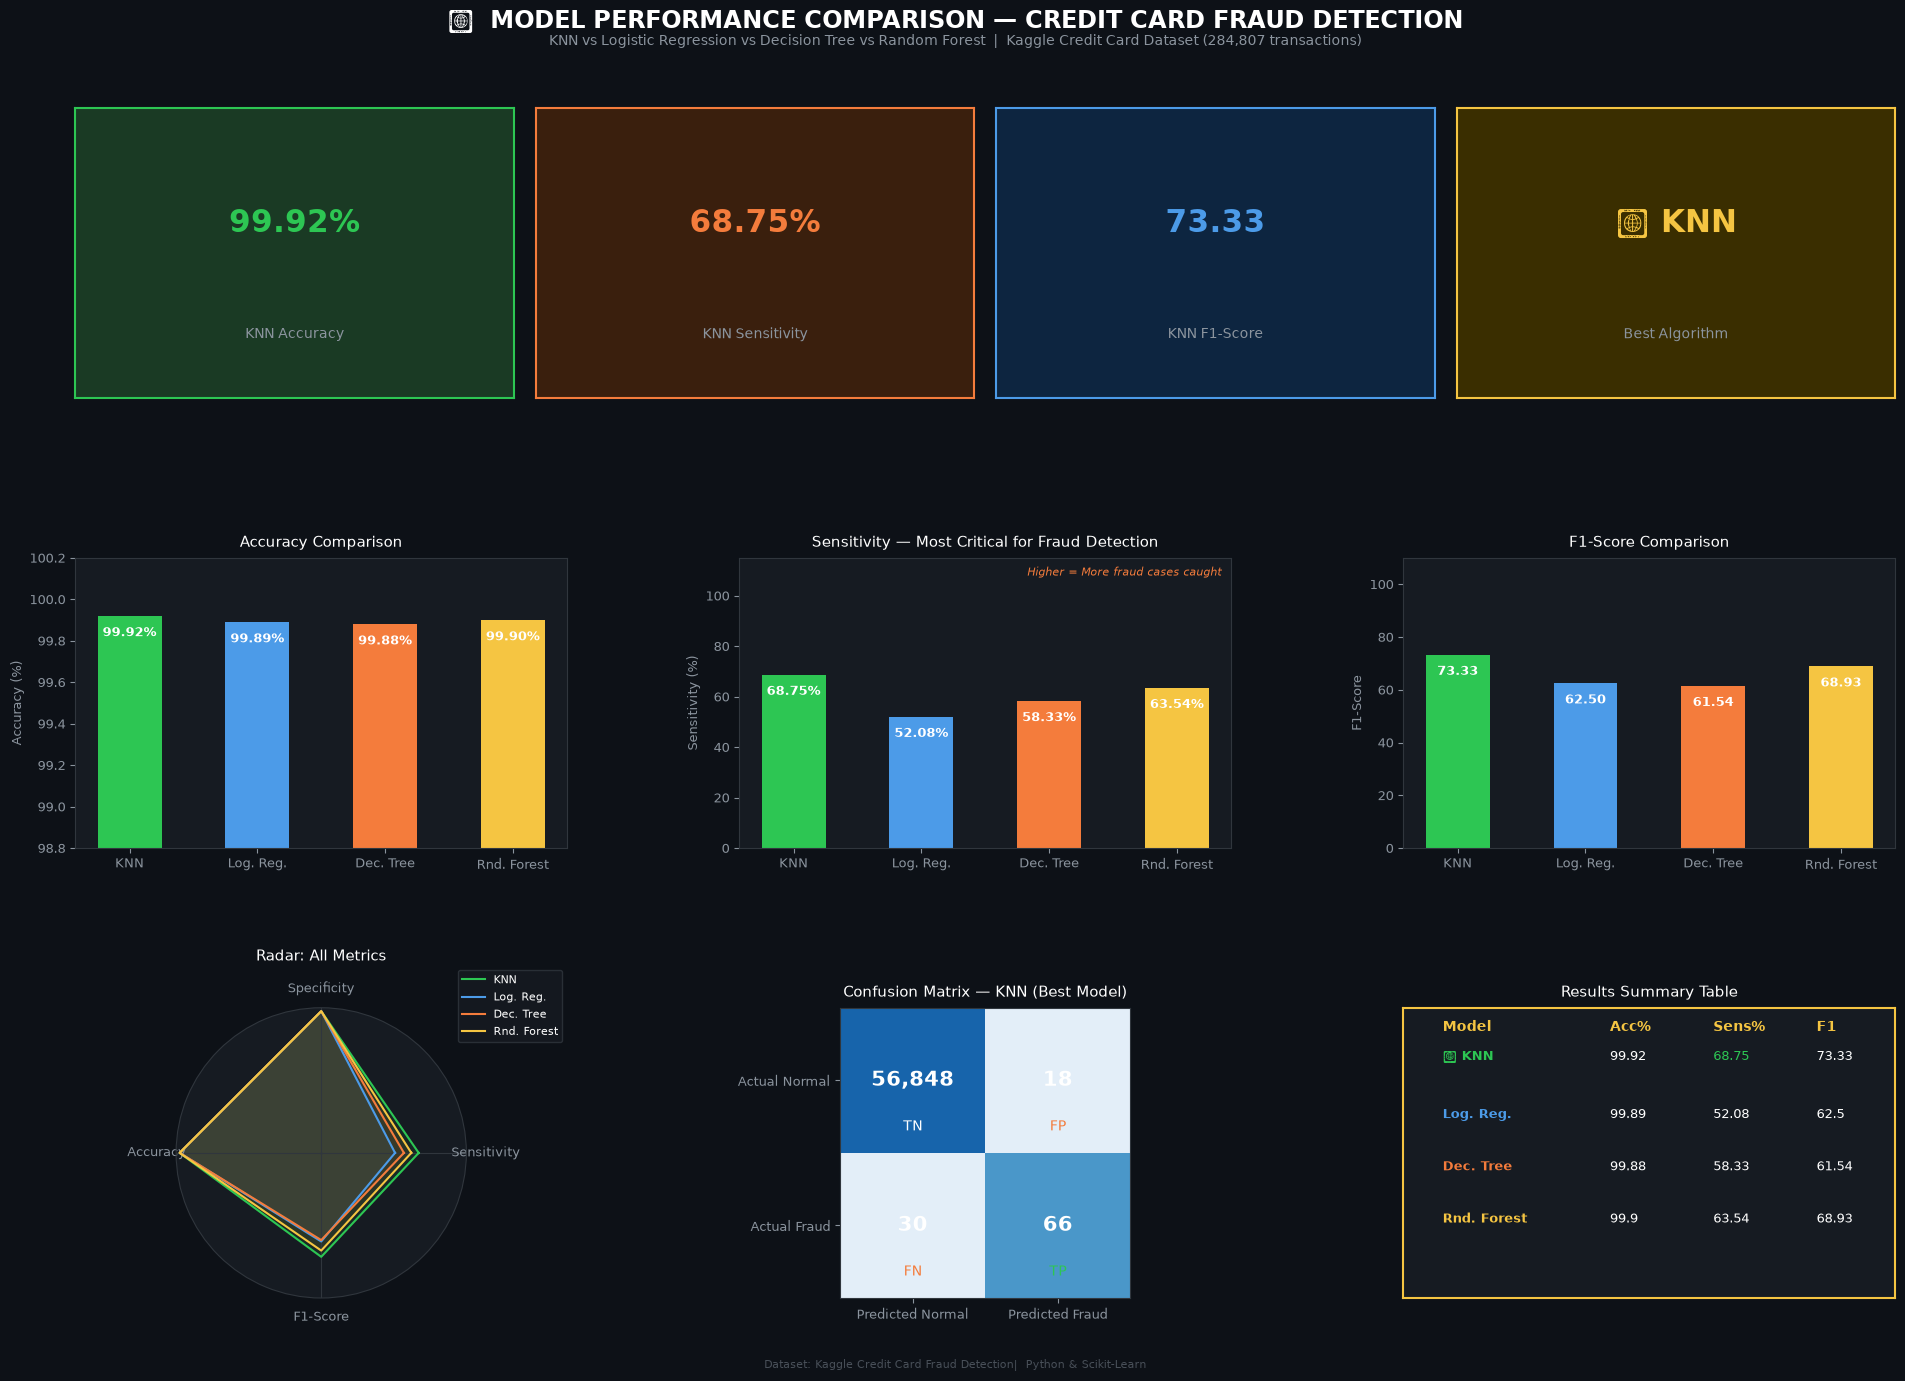


✅ Dashboard saved to: ../results/model_performance_comparison.png


In [88]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import os

# ── Colour palette ──────────────────────────────────────────
BG      = '#0d1117'
CARD_BG = '#161b22'
COLORS  = ['#2dc653', '#4c9be8', '#f47c3c', '#f5c542']
MODELS  = results['Model']
ACC     = results['Accuracy']
SENS    = results['Sensitivity']
SPEC    = results['Specificity']
F1      = results['F1_Score']

fig = plt.figure(figsize=(20, 14), facecolor=BG)
fig.suptitle('🔒  MODEL PERFORMANCE COMPARISON — CREDIT CARD FRAUD DETECTION',
             color='white', fontsize=17, fontweight='bold', y=0.98)
fig.text(0.5, 0.955,
         'KNN vs Logistic Regression vs Decision Tree vs Random Forest  |  '
         'Kaggle Credit Card Dataset (284,807 transactions)',
         ha='center', color='#8b949e', fontsize=10)

gs = gridspec.GridSpec(3, 3, figure=fig,
                       hspace=0.55, wspace=0.35,
                       top=0.91, bottom=0.06,
                       left=0.06, right=0.97)

# ── Helper: style an axes ───────────────────────────────────
def style_ax(ax, title, xlabel='', ylabel=''):
    ax.set_facecolor(CARD_BG)
    for spine in ax.spines.values(): spine.set_edgecolor('#30363d')
    ax.tick_params(colors='#8b949e', labelsize=9)
    ax.set_title(title, color='white', fontsize=11, pad=8)
    if xlabel: ax.set_xlabel(xlabel, color='#8b949e', fontsize=9)
    if ylabel: ax.set_ylabel(ylabel, color='#8b949e', fontsize=9)
    ax.yaxis.label.set_color('#8b949e')
    ax.xaxis.label.set_color('#8b949e')

def bar_labels(ax, vals, fmt='{:.2f}%', yoffset=0.02):
    ylim = ax.get_ylim()
    rng  = ylim[1] - ylim[0]
    for bar, v in zip(ax.patches, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() - rng*0.08,
                fmt.format(v),
                ha='center', va='bottom',
                color='white', fontsize=9, fontweight='bold')

# ── KPI cards (row 0, col 0-2) ──────────────────────────────
kpi_data = [
    (f'{ACC[0]}%',  'KNN Accuracy',   '#2dc653', '#1a3a24'),
    (f'{SENS[0]}%', 'KNN Sensitivity', '#f47c3c', '#3a1f0d'),
    (f'{F1[0]}',    'KNN F1-Score',    '#4c9be8', '#0d2540'),
    ('🏆 KNN',       'Best Algorithm',  '#f5c542', '#3a2e00'),
]
kpi_gs = gridspec.GridSpecFromSubplotSpec(1, 4, subplot_spec=gs[0, :],
                                           wspace=0.05)
for k, (val, lbl, fg, bg_col) in enumerate(kpi_data):
    ax = fig.add_subplot(kpi_gs[k])
    ax.set_facecolor(bg_col)
    for spine in ax.spines.values():
        spine.set_edgecolor(fg); spine.set_linewidth(1.5)
    ax.set_xticks([]); ax.set_yticks([])
    ax.text(0.5, 0.60, val,  transform=ax.transAxes,
            ha='center', va='center', color=fg,
            fontsize=22, fontweight='bold')
    ax.text(0.5, 0.22, lbl, transform=ax.transAxes,
            ha='center', va='center', color='#8b949e', fontsize=10)

# ── Accuracy bar chart ──────────────────────────────────────
ax1 = fig.add_subplot(gs[1, 0])
bars = ax1.bar(MODELS, ACC, color=COLORS, width=0.5)
ax1.set_ylim(98.8, 100.2)
style_ax(ax1, 'Accuracy Comparison', ylabel='Accuracy (%)')
bar_labels(ax1, ACC)

# ── Sensitivity bar chart ───────────────────────────────────
ax2 = fig.add_subplot(gs[1, 1])
bars2 = ax2.bar(MODELS, SENS, color=COLORS, width=0.5)
ax2.set_ylim(0, 115)
style_ax(ax2, 'Sensitivity — Most Critical for Fraud Detection',
         ylabel='Sensitivity (%)')
ax2.text(0.98, 0.97, 'Higher = More fraud cases caught',
         transform=ax2.transAxes, ha='right', va='top',
         color='#f47c3c', fontsize=8, style='italic')
bar_labels(ax2, SENS)

# ── F1-Score bar chart ──────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 2])
ax3.bar(MODELS, F1, color=COLORS, width=0.5)
ax3.set_ylim(0, 110)
style_ax(ax3, 'F1-Score Comparison', ylabel='F1-Score')
bar_labels(ax3, F1, fmt='{:.2f}')

# ── Radar chart ─────────────────────────────────────────────
ax_radar = fig.add_subplot(gs[2, 0], polar=True)
ax_radar.set_facecolor(CARD_BG)
categories = ['Sensitivity', 'Specificity', 'Accuracy', 'F1-Score']
N = len(categories)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles += angles[:1]
radar_data = [
    [SENS[i]/100, SPEC[i]/100, ACC[i]/100, F1[i]/100]
    for i in range(4)
]
for i, (row, col) in enumerate(zip(radar_data, COLORS)):
    vals = row + row[:1]
    ax_radar.plot(angles, vals, color=col, linewidth=1.5, label=MODELS[i])
    ax_radar.fill(angles, vals, color=col, alpha=0.08)
ax_radar.set_xticks(angles[:-1])
ax_radar.set_xticklabels(categories, color='#8b949e', fontsize=9)
ax_radar.set_yticks([])
ax_radar.set_title('Radar: All Metrics', color='white', fontsize=11, pad=15)
ax_radar.spines['polar'].set_edgecolor('#30363d')
ax_radar.yaxis.grid(True, color='#30363d')
ax_radar.xaxis.grid(True, color='#30363d')
ax_radar.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15),
                fontsize=8, labelcolor='white',
                facecolor=CARD_BG, edgecolor='#30363d')

# ── Confusion matrix (KNN best model) ───────────────────────
ax_cm = fig.add_subplot(gs[2, 1])
cm_vals = np.array([[KNN_TN, KNN_FP], [KNN_FN, KNN_TP]])
im = ax_cm.imshow([[0.8, 0.1], [0.1, 0.6]], cmap='Blues', vmin=0, vmax=1)
ax_cm.set_facecolor(CARD_BG)
labels = [['TN', 'FP'], ['FN', 'TP']]
cell_colors = [['white', '#f47c3c'], ['#f47c3c', '#2dc653']]
for i in range(2):
    for j in range(2):
        ax_cm.text(j, i, f'{cm_vals[i,j]:,}',
                   ha='center', va='center',
                   color='white', fontsize=15, fontweight='bold')
        ax_cm.text(j, i+0.32, labels[i][j],
                   ha='center', va='center',
                   color=cell_colors[i][j], fontsize=10)
ax_cm.set_xticks([0, 1])
ax_cm.set_yticks([0, 1])
ax_cm.set_xticklabels(['Predicted Normal', 'Predicted Fraud'],
                       color='#8b949e', fontsize=9)
ax_cm.set_yticklabels(['Actual Normal', 'Actual Fraud'],
                       color='#8b949e', fontsize=9)
style_ax(ax_cm, 'Confusion Matrix — KNN (Best Model)')

# ── Results summary table ───────────────────────────────────
ax_tbl = fig.add_subplot(gs[2, 2])
ax_tbl.set_facecolor(CARD_BG)
for spine in ax_tbl.spines.values():
    spine.set_edgecolor('#f5c542'); spine.set_linewidth(1.5)
ax_tbl.set_xticks([]); ax_tbl.set_yticks([])
ax_tbl.set_title('Results Summary Table', color='white', fontsize=11, pad=8)
col_headers = ['Model', 'Acc%', 'Sens%', 'F1']
col_x = [0.08, 0.42, 0.63, 0.84]
row_y = [0.82, 0.62, 0.44, 0.26, 0.08]
for cx, hdr in zip(col_x, col_headers):
    ax_tbl.text(cx, 0.92, hdr, transform=ax_tbl.transAxes,
                color='#f5c542', fontsize=10, fontweight='bold')
tbl_rows = [
    ('🏆 KNN',       ACC[0], SENS[0], F1[0], COLORS[0]),
    ('Log. Reg.',    ACC[1], SENS[1], F1[1], COLORS[1]),
    ('Dec. Tree',    ACC[2], SENS[2], F1[2], COLORS[2]),
    ('Rnd. Forest',  ACC[3], SENS[3], F1[3], COLORS[3]),
]
for (name, acc, sens, f1, col), ry in zip(tbl_rows, row_y):
    ax_tbl.text(col_x[0], ry, name, transform=ax_tbl.transAxes,
                color=col, fontsize=9, fontweight='bold')
    ax_tbl.text(col_x[1], ry, f'{acc}',  transform=ax_tbl.transAxes,
                color='white', fontsize=9)
    sens_col = '#2dc653' if sens == max(SENS) else 'white'
    ax_tbl.text(col_x[2], ry, f'{sens}', transform=ax_tbl.transAxes,
                color=sens_col, fontsize=9)
    ax_tbl.text(col_x[3], ry, f'{f1}',   transform=ax_tbl.transAxes,
                color='white', fontsize=9)

# ── Footer ──────────────────────────────────────────────────
fig.text(0.5, 0.01,
         'Dataset: Kaggle Credit Card Fraud Detection|  Python & Scikit-Learn',
         ha='center', color='#484f58', fontsize=8)

# ── Save ────────────────────────────────────────────────────
out_path = '../results/model_performance_comparison.png'
os.makedirs(os.path.dirname(out_path), exist_ok=True)
plt.savefig(out_path, dpi=150, bbox_inches='tight',
            facecolor=BG, edgecolor='none')
plt.show()
print(f'\n✅ Dashboard saved to: {out_path}')